# Visualize Token Graphs Across Context Lengths

This Visualize notebook loads the cache produced by `Generate-token-graphs-across-context-lengths.ipynb` and generates the attention-induced token-graph figure described under **Token-Graph Visualization Pipeline** in the Methods section. Rows show final-layer Llama-3.2-3B results for representative constant, period-16 logistic-map, and chaotic logistic-map ($r=4.0$) inputs.

The first five columns show token graphs at $N \in \{100, 200, 300, 400, 500\}$. Node positions use attention-weighted Fruchterman–Reingold layouts with matched initialization across inputs at each $N$; edge thickness encodes attention weight, and only edges above $2.5/N$ are displayed. Node colors encode the leading three uncentered hidden-state SVD coordinates, with the $N=500$ projections shown in the rightmost column. Circles mark numeric tokens and triangles mark separator tokens.

Set imports, retained inputs, and figure styles.

In [1]:
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch

# Analysis windows
REFERENCE_CONTEXT_TOKENS = 1000
CONTEXT_TOKEN_COUNTS = (100, 200, 300, 400, 500)
HIDDEN_STATE_CONTEXT_TOKENS = 500
HIDDEN_STATE_CONTEXT_FRAC = HIDDEN_STATE_CONTEXT_TOKENS / REFERENCE_CONTEXT_TOKENS
SVD_COMPONENTS = (1, 2, 3)
ORIENT_COMPONENT_SIGNS_BY_TOKEN_ORDER = False

# Run from this notebook's directory; load data and save figures locally.
CONTEXT_GRAPH_DATA_DIR = Path("processed_context_length_last_layer_graph_data")
FIGURE_OUTPUT_DIR = Path("figure")

# Retained input order
DATA_ORDER = (
    "Constant 500",
    "Logistic r=3.566",
    "Logistic r=4.0",
)

DATA_TITLE_OVERRIDES = {
    "Constant 500": "Constant",
    "Logistic r=3.566": "Period 16",
    "Logistic r=4.0": "Chaotic",
}
DATA_TITLE_SUFFIXES = {}

# Combined 3 x 6 layout
DISPLAY_DPI = 150
SAVE_DPI = 300
COMBINED_GRID_WIDTH_RATIOS = (1.0, 0.087) * (len(CONTEXT_TOKEN_COUNTS) - 1) + (1.0, 0.174, 1.34)
COMBINED_SAVE_FILENAME = "last_layer_context_length_graphs_with_hidden_states.pdf"
ROW_LABEL_X = 0.083
ROW_LABEL_FONT_SIZE = 10.4
CONTEXT_GUIDE_Y = 0.118
BOTTOM_LABEL_Y = 0.10
HIDDEN_STATE_LABEL_X_OFFSET = -0.0115
CONTEXT_GUIDE_FONT_SIZE = 10.4
DYNAMICAL_GUIDE_ARROW_X = 0.057
DYNAMICAL_GUIDE_LABEL_X = 0.041
DYNAMICAL_GUIDE_FONT_SIZE = 10.4
GUIDE_ARROW_COLOR = "#4D4D4D"
GUIDE_LABEL_COLOR = "#2F2F2F"
GUIDE_ARROW_LINE_WIDTH = 2

# Attention-graph style
GRAPH_EDGE_THRESHOLD_FACTOR = 2.5
GRAPH_EDGE_BASE_GRAY = 0.15
GRAPH_EDGE_ALPHA_MIN = 0.06
GRAPH_EDGE_ALPHA_SPAN = 0.52
GRAPH_EDGE_ALPHA_GAMMA = 0.85
GRAPH_EDGE_LW_MIN = 0.27
GRAPH_EDGE_LW_SPAN = 1.50
GRAPH_EDGE_LW_GAMMA = 0.90
GRAPH_EDGE_STYLE_BINS = 20
GRAPH_NODE_SIZE = 13.2
GRAPH_DELIMITER_SIZE = 17.5
GRAPH_NODE_SIZE_FLOOR = 5.3
GRAPH_DELIMITER_SIZE_FLOOR = 6.6
GRAPH_NODE_SIZE_SCALE = 0.495
GRAPH_X_MARGIN = 0.01
GRAPH_Y_MARGIN = 0.06

# Hidden-state projection style
HIDDEN_STATE_VERTICAL_SHIFT_FRAC = 0.05
SVD_STATE_NODE_SIZE = 5.85
SVD_DELIMITER_NODE_SIZE = 13.2
SVD_NODE_ALPHA = 0.98
SVD_DELIMITER_EDGE_COLOR = "#888888"
SVD_DELIMITER_EDGE_WIDTH = 0.31
SVD_AXIS_MARGIN_FRAC = 0.03
SVD_VIEW_ELEV = 15
SVD_VIEW_AZIM = 45
SVD_AXIS_LABEL_FONT_SIZE = 7.04
SVD_TICK_LABEL_FONT_SIZE = 5.92
SVD_GRID_COLOR = "#D6D6D6"
SVD_GRID_LINE_WIDTH = 0.45
SVD_PANE_COLOR = (0.985, 0.985, 0.985, 0.45)
SVD_AXIS_LINE_COLOR = "black"

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["figure.dpi"] = DISPLAY_DPI
plt.rcParams["savefig.dpi"] = SAVE_DPI

Load and validate the processed graph archives.

In [2]:
CONTEXT_GRAPH_REQUIRED_KEYS = (
    "layer_indices",
    "Wbar",
    "layout_positions",
    "svd_projection_coords",
    "is_delimiter",
)
HIDDEN_STATE_REQUIRED_KEYS = (
    "layer_indices",
    "svd_projection_coords",
    "is_delimiter",
)


def panel_title(data_name):
    data_name = str(data_name)
    title = DATA_TITLE_OVERRIDES.get(data_name, data_name)
    suffix = DATA_TITLE_SUFFIXES.get(data_name)
    return f"{title} ({suffix})" if suffix else title


def context_fraction_label(frac):
    return f"context{int(round(100 * float(frac)))}"


def context_frac_from_token_count(num_tokens):
    return float(int(num_tokens)) / float(REFERENCE_CONTEXT_TOKENS)


def safe_data_stem(data_name, frac):
    name = str(data_name).replace("=", "_").replace(".", "_")
    name = re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_").lower()
    return f"{name}_{context_fraction_label(frac)}"


def context_graph_data_path(data_name, num_tokens, data_dir=CONTEXT_GRAPH_DATA_DIR):
    frac = context_frac_from_token_count(num_tokens)
    return Path(data_dir) / f"{safe_data_stem(data_name, frac)}_graph_data.npz"


def hidden_state_data_path(
    data_name, frac=HIDDEN_STATE_CONTEXT_FRAC, data_dir=CONTEXT_GRAPH_DATA_DIR
):
    return Path(data_dir) / f"{safe_data_stem(data_name, frac)}_graph_data.npz"


def load_npz_arrays(path, required_keys):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    with np.load(path, allow_pickle=False) as npz:
        missing = [key for key in required_keys if key not in npz.files]
        if missing:
            raise KeyError(f"{path} is missing required arrays: {missing}")
        return {key: npz[key] for key in required_keys}


def load_context_graph_data(data_name, num_tokens, data_dir=CONTEXT_GRAPH_DATA_DIR):
    path = context_graph_data_path(data_name, num_tokens, data_dir=data_dir)
    return load_npz_arrays(path, CONTEXT_GRAPH_REQUIRED_KEYS)


def load_hidden_state_data(
    data_name, frac=HIDDEN_STATE_CONTEXT_FRAC, data_dir=CONTEXT_GRAPH_DATA_DIR
):
    path = hidden_state_data_path(data_name, frac=frac, data_dir=data_dir)
    return load_npz_arrays(path, HIDDEN_STATE_REQUIRED_KEYS)


def layer_offset(processed_data, layer_index):
    layer_indices = np.asarray(processed_data["layer_indices"], dtype=int)
    matches = np.nonzero(layer_indices == int(layer_index))[0]
    if matches.size == 0:
        available = (
            ", ".join(str(int(layer)) for layer in layer_indices) if layer_indices.size else "none"
        )
        raise ValueError(
            f"Layer {layer_index} is unavailable. Available one-based layers: {available}"
        )
    return int(matches[0])


def available_layer_indices(
    data_name=DATA_ORDER[0],
    num_tokens=CONTEXT_TOKEN_COUNTS[-1],
    data_dir=CONTEXT_GRAPH_DATA_DIR,
):
    processed_data = load_context_graph_data(data_name, num_tokens, data_dir=data_dir)
    return np.asarray(processed_data["layer_indices"], dtype=int)


def check_combined_figure_data(
    data_names=DATA_ORDER,
    context_token_counts=CONTEXT_TOKEN_COUNTS,
    context_data_dir=CONTEXT_GRAPH_DATA_DIR,
):
    errors = []
    for data_name in data_names:
        for num_tokens in context_token_counts:
            path = context_graph_data_path(data_name, num_tokens, data_dir=context_data_dir)
            try:
                load_context_graph_data(data_name, num_tokens, data_dir=context_data_dir)
            except (OSError, KeyError, ValueError) as exc:
                errors.append(f"{path}: {exc}")

        signal_path = hidden_state_data_path(data_name, data_dir=context_data_dir)
        try:
            load_hidden_state_data(data_name, data_dir=context_data_dir)
        except (OSError, KeyError, ValueError) as exc:
            errors.append(f"{signal_path}: {exc}")

    if errors:
        raise ValueError("Combined-figure cache validation failed:\n" + "\n".join(errors))

Prepare and draw attention-induced token graphs.

In [3]:
def minmax_scale_rgb_channels(coords, fill_value=0.5, eps=1e-12):
    coords = np.asarray(coords, dtype=float)
    if coords.ndim == 1:
        coords = coords[:, None]
    if coords.ndim != 2:
        raise ValueError("coords must be 2D (num_tokens x num_components)")

    rgb = np.full((coords.shape[0], 3), float(fill_value), dtype=float)
    for component_idx in range(min(3, coords.shape[1])):
        values = np.asarray(coords[:, component_idx], dtype=float)
        finite = np.isfinite(values)
        if not np.any(finite):
            continue
        value_min = float(np.min(values[finite]))
        value_max = float(np.max(values[finite]))
        if (value_max - value_min) > float(eps):
            rgb[finite, component_idx] = (values[finite] - value_min) / (value_max - value_min)
    rgb[~np.isfinite(rgb)] = float(fill_value)
    return np.clip(rgb, 0.0, 1.0)


def edge_weight_threshold_from_uniform(n_nodes, factor=GRAPH_EDGE_THRESHOLD_FACTOR):
    n_nodes = int(n_nodes)
    return float("inf") if n_nodes <= 0 else float(factor) / float(n_nodes)


def select_draw_edges(W, threshold_factor=GRAPH_EDGE_THRESHOLD_FACTOR):
    W = np.asarray(W, dtype=float).copy()
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError("W must be square")
    n_nodes = W.shape[0]
    if n_nodes < 2:
        return np.empty(0, dtype=int), np.empty(0, dtype=int), np.empty(0, dtype=float)

    W[~np.isfinite(W)] = 0.0
    np.fill_diagonal(W, 0.0)
    upper_indices = np.triu_indices(n_nodes, k=1)
    upper_weights = W[upper_indices]
    mask = upper_weights > edge_weight_threshold_from_uniform(n_nodes, threshold_factor)
    chosen = np.nonzero(mask)[0]
    if chosen.size == 0:
        return np.empty(0, dtype=int), np.empty(0, dtype=int), np.empty(0, dtype=float)
    chosen = chosen[np.argsort(upper_weights[chosen])[::-1]]
    return upper_indices[0][chosen], upper_indices[1][chosen], upper_weights[chosen]


def collect_attention_graph_panels(
    layer_index,
    data_names=DATA_ORDER,
    context_token_counts=CONTEXT_TOKEN_COUNTS,
    data_dir=CONTEXT_GRAPH_DATA_DIR,
):
    panel_data = {}
    all_edge_weights = []
    for data_name in data_names:
        for num_tokens in context_token_counts:
            processed_data = load_context_graph_data(data_name, num_tokens, data_dir=data_dir)
            offset = layer_offset(processed_data, layer_index)
            Wbar = np.asarray(processed_data["Wbar"], dtype=np.float32)[offset]
            coords = np.asarray(processed_data["svd_projection_coords"], dtype=np.float32)[offset]
            _, _, edge_weights = select_draw_edges(Wbar)
            if edge_weights.size:
                all_edge_weights.append(edge_weights)
            panel_data[(str(data_name), int(num_tokens))] = dict(
                Wbar=Wbar,
                layout_positions=np.asarray(processed_data["layout_positions"], dtype=np.float32)[
                    offset
                ],
                rgb_colors=minmax_scale_rgb_channels(coords).astype(np.float32),
                is_delimiter=np.asarray(processed_data["is_delimiter"], dtype=bool),
            )

    if all_edge_weights:
        all_edge_weights = np.concatenate(all_edge_weights)
        edge_weight_limits = (float(np.min(all_edge_weights)), float(np.max(all_edge_weights)))
    else:
        edge_weight_limits = (0.0, 0.0)
    return panel_data, edge_weight_limits


def draw_attention_graph_on_ax(ax, payload, edge_weight_limits):
    W = np.asarray(payload["Wbar"], dtype=float)
    xy = np.asarray(payload["layout_positions"], dtype=float)
    rgb = np.asarray(payload["rgb_colors"], dtype=float)
    is_delimiter = np.asarray(payload["is_delimiter"], dtype=bool)
    n_nodes = min(W.shape[0], xy.shape[0], rgb.shape[0], is_delimiter.shape[0])
    if n_nodes == 0:
        ax.axis("off")
        return

    W = W[:n_nodes, :n_nodes]
    xy = xy[:n_nodes]
    rgb = np.clip(rgb[:n_nodes], 0.0, 1.0)
    is_delimiter = is_delimiter[:n_nodes]
    i_idx, j_idx, edge_weights = select_draw_edges(W)

    if edge_weights.size:
        segments = np.stack([xy[i_idx], xy[j_idx]], axis=1)
        weight_min, weight_max = edge_weight_limits
        if weight_max > weight_min:
            scaled_weights = np.clip(
                (edge_weights - weight_min) / (weight_max - weight_min), 0.0, 1.0
            )
        else:
            scaled_weights = np.ones_like(edge_weights)
        bin_indices = np.minimum(
            (scaled_weights * GRAPH_EDGE_STYLE_BINS).astype(int), GRAPH_EDGE_STYLE_BINS - 1
        )
        for bin_idx in range(GRAPH_EDGE_STYLE_BINS):
            mask = bin_indices == bin_idx
            if not np.any(mask):
                continue
            bin_center = (bin_idx + 0.5) / GRAPH_EDGE_STYLE_BINS
            alpha = (
                GRAPH_EDGE_ALPHA_MIN + GRAPH_EDGE_ALPHA_SPAN * bin_center**GRAPH_EDGE_ALPHA_GAMMA
            )
            line_width = GRAPH_EDGE_LW_MIN + GRAPH_EDGE_LW_SPAN * bin_center**GRAPH_EDGE_LW_GAMMA
            color = (GRAPH_EDGE_BASE_GRAY, GRAPH_EDGE_BASE_GRAY, GRAPH_EDGE_BASE_GRAY, alpha)
            ax.add_collection(
                LineCollection(segments[mask], colors=[color], linewidths=line_width, zorder=2)
            )

    state_mask = ~is_delimiter
    if np.any(state_mask):
        ax.scatter(
            xy[state_mask, 0],
            xy[state_mask, 1],
            c=rgb[state_mask],
            s=max(GRAPH_NODE_SIZE_FLOOR, GRAPH_NODE_SIZE * 0.8 * GRAPH_NODE_SIZE_SCALE),
            alpha=0.95,
            marker="o",
            edgecolors="none",
            zorder=3,
        )
    if np.any(is_delimiter):
        ax.scatter(
            xy[is_delimiter, 0],
            xy[is_delimiter, 1],
            c=rgb[is_delimiter],
            s=max(GRAPH_DELIMITER_SIZE_FLOOR, GRAPH_DELIMITER_SIZE * 0.8 * GRAPH_NODE_SIZE_SCALE),
            alpha=0.95,
            marker="^",
            edgecolors="none",
            zorder=4,
        )
    ax.set_aspect("equal", adjustable="box")
    ax.margins(x=GRAPH_X_MARGIN, y=GRAPH_Y_MARGIN)
    ax.axis("off")

Prepare and draw three-dimensional hidden-state projections.

In [4]:
def component_indices_from_one_based(svd_components):
    components = tuple(int(component) for component in svd_components)
    if len(components) != 3 or any(component < 1 for component in components):
        raise ValueError("Choose exactly three positive, one-based SVD components.")
    return tuple(component - 1 for component in components)


def orient_component_signs_by_token_order(coords, eps=1e-12):
    coords = np.asarray(coords, dtype=float).copy()
    if coords.ndim != 2 or coords.shape[0] < 2:
        return coords
    token_order = np.arange(coords.shape[0], dtype=float)
    token_order -= np.mean(token_order)
    for component_idx in range(coords.shape[1]):
        values = coords[:, component_idx]
        finite = np.isfinite(values)
        if np.count_nonzero(finite) < 2:
            continue
        centered_values = values[finite] - np.mean(values[finite])
        score = float(np.dot(token_order[finite], centered_values))
        if score < -eps:
            coords[:, component_idx] *= -1.0
    return coords


def collect_hidden_state_panels(
    layer_index,
    data_names=DATA_ORDER,
    svd_components=SVD_COMPONENTS,
    frac=HIDDEN_STATE_CONTEXT_FRAC,
    data_dir=CONTEXT_GRAPH_DATA_DIR,
    orient_signs=ORIENT_COMPONENT_SIGNS_BY_TOKEN_ORDER,
):
    component_indices = component_indices_from_one_based(svd_components)
    panel_data = {}
    for data_name in data_names:
        processed_data = load_hidden_state_data(data_name, frac=frac, data_dir=data_dir)
        offset = layer_offset(processed_data, layer_index)
        all_coords = np.asarray(processed_data["svd_projection_coords"], dtype=float)[offset]
        if max(component_indices) >= all_coords.shape[1]:
            raise ValueError(f"{data_name} does not contain SVD components {svd_components}.")
        coords = all_coords[:, component_indices]
        if orient_signs:
            coords = orient_component_signs_by_token_order(coords)
        panel_data[str(data_name)] = dict(
            coords=coords,
            rgb_colors=minmax_scale_rgb_channels(coords).astype(np.float32),
            is_delimiter=np.asarray(processed_data["is_delimiter"], dtype=bool),
        )
    return panel_data


def robust_3d_axis_limits(coords, margin_frac=None):
    coords = np.asarray(coords, dtype=float)
    if margin_frac is None:
        margin_frac = SVD_AXIS_MARGIN_FRAC
    finite = np.isfinite(coords).all(axis=1)
    if not np.any(finite):
        return [(-1.0, 1.0)] * 3
    lows = np.min(coords[finite], axis=0)
    highs = np.max(coords[finite], axis=0)
    spans = highs - lows
    bad = (~np.isfinite(spans)) | (spans <= 0)
    if np.any(bad):
        centers = np.nanmedian(coords[finite], axis=0)
        lows[bad] = centers[bad] - 0.5
        highs[bad] = centers[bad] + 0.5
        spans = highs - lows
    margins = float(margin_frac) * spans
    return [
        (float(low - margin), float(high + margin))
        for low, high, margin in zip(lows, highs, margins)
    ]


def draw_hidden_state_projection_on_ax(ax, payload, axis_limits, show_axis_labels=True):
    coords = np.asarray(payload["coords"], dtype=float)
    rgb = np.asarray(payload["rgb_colors"], dtype=float)
    is_delimiter = np.asarray(payload["is_delimiter"], dtype=bool)
    n_nodes = min(coords.shape[0], rgb.shape[0], is_delimiter.shape[0])
    coords = coords[:n_nodes]
    rgb = np.clip(rgb[:n_nodes], 0.0, 1.0)
    is_delimiter = is_delimiter[:n_nodes]
    finite = np.isfinite(coords).all(axis=1) & np.isfinite(rgb).all(axis=1)

    state_mask = finite & ~is_delimiter
    if np.any(state_mask):
        ax.scatter(
            coords[state_mask, 0],
            coords[state_mask, 1],
            coords[state_mask, 2],
            c=rgb[state_mask],
            s=SVD_STATE_NODE_SIZE,
            marker="o",
            alpha=SVD_NODE_ALPHA,
            edgecolors="none",
            depthshade=False,
        )
    delimiter_mask = finite & is_delimiter
    if np.any(delimiter_mask):
        ax.scatter(
            coords[delimiter_mask, 0],
            coords[delimiter_mask, 1],
            coords[delimiter_mask, 2],
            c=rgb[delimiter_mask],
            s=SVD_DELIMITER_NODE_SIZE,
            marker="^",
            alpha=SVD_NODE_ALPHA,
            edgecolors=SVD_DELIMITER_EDGE_COLOR,
            linewidths=SVD_DELIMITER_EDGE_WIDTH,
            depthshade=False,
        )
    style_hidden_state_axis(ax, axis_limits, show_axis_labels=show_axis_labels)


def style_hidden_state_axis(ax, axis_limits, svd_components=SVD_COMPONENTS, show_axis_labels=True):
    ax.set_xlim(*axis_limits[0])
    ax.set_ylim(*axis_limits[1])
    ax.set_zlim(*axis_limits[2])
    ax.set_box_aspect((1.0, 1.0, 1.0))
    ax.view_init(elev=SVD_VIEW_ELEV, azim=SVD_VIEW_AZIM)
    ax.set_proj_type("persp")
    ax.set_xlabel(
        f"SVD-{svd_components[0]} score" if show_axis_labels else "",
        fontsize=SVD_AXIS_LABEL_FONT_SIZE,
        labelpad=-6,
    )
    ax.set_ylabel(
        f"SVD-{svd_components[1]} score" if show_axis_labels else "",
        fontsize=SVD_AXIS_LABEL_FONT_SIZE,
        labelpad=-6,
    )
    ax.set_zlabel("")
    if show_axis_labels:
        ax.text2D(
            -0.085,
            0.52,
            f"SVD-{svd_components[2]} score",
            transform=ax.transAxes,
            rotation=90,
            ha="center",
            va="center",
            fontsize=SVD_AXIS_LABEL_FONT_SIZE,
        )
    ax.tick_params(
        axis="both", which="major", labelsize=SVD_TICK_LABEL_FONT_SIZE, pad=-2, colors="#333333"
    )
    ax.zaxis.set_tick_params(labelsize=SVD_TICK_LABEL_FONT_SIZE, pad=-2, colors="#333333")
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_major_locator(mpl.ticker.MaxNLocator(nbins=3, min_n_ticks=3))
        axis.pane.set_facecolor(SVD_PANE_COLOR)
        axis.pane.set_edgecolor(SVD_PANE_COLOR)
        axis._axinfo["grid"]["color"] = SVD_GRID_COLOR
        axis._axinfo["grid"]["linewidth"] = SVD_GRID_LINE_WIDTH
        axis._axinfo["axisline"]["color"] = SVD_AXIS_LINE_COLOR
        axis._axinfo["axisline"]["linewidth"] = 0.8

Assemble the combined context-length figure.

In [5]:
def add_combined_figure_labels(
    fig, graph_axes, hidden_state_axes, data_names, context_token_counts
):
    fig.canvas.draw()
    first_graph_position = graph_axes[-1, 0].get_position()
    last_graph_position = graph_axes[-1, -1].get_position()
    context_arrow_start = first_graph_position.x0
    context_arrow_end = last_graph_position.x1
    context_arrow_start += 0.05 * (context_arrow_end - context_arrow_start)
    fig.add_artist(
        FancyArrowPatch(
            (context_arrow_start, CONTEXT_GUIDE_Y),
            (context_arrow_end, CONTEXT_GUIDE_Y),
            transform=fig.transFigure,
            arrowstyle="->",
            mutation_scale=15,
            linewidth=GUIDE_ARROW_LINE_WIDTH,
            color=GUIDE_ARROW_COLOR,
            clip_on=False,
        )
    )
    fig.text(
        0.5 * (context_arrow_start + context_arrow_end),
        BOTTOM_LABEL_Y,
        "Increasing context length",
        ha="center",
        va="top",
        fontsize=CONTEXT_GUIDE_FONT_SIZE,
        color=GUIDE_LABEL_COLOR,
    )

    hidden_position = hidden_state_axes[-1].get_position()
    fig.text(
        hidden_position.x0 + 0.5 * hidden_position.width + HIDDEN_STATE_LABEL_X_OFFSET,
        BOTTOM_LABEL_Y,
        "Hidden-state projection",
        ha="center",
        va="top",
        fontsize=CONTEXT_GUIDE_FONT_SIZE,
    )

    top_position = graph_axes[0, 0].get_position()
    bottom_position = graph_axes[-1, 0].get_position()
    dynamical_arrow_start_y = top_position.y1 - 0.012
    dynamical_arrow_end_y = bottom_position.y0 + 0.012
    dynamical_arrow_start_y -= 0.05 * (dynamical_arrow_start_y - dynamical_arrow_end_y)
    fig.add_artist(
        FancyArrowPatch(
            (DYNAMICAL_GUIDE_ARROW_X, dynamical_arrow_start_y),
            (DYNAMICAL_GUIDE_ARROW_X, dynamical_arrow_end_y),
            transform=fig.transFigure,
            arrowstyle="->",
            mutation_scale=15,
            linewidth=GUIDE_ARROW_LINE_WIDTH,
            color=GUIDE_ARROW_COLOR,
            clip_on=False,
        )
    )
    fig.text(
        DYNAMICAL_GUIDE_LABEL_X,
        0.5 * (dynamical_arrow_start_y + dynamical_arrow_end_y),
        "Increasing dynamical complexity",
        rotation=90,
        ha="center",
        va="center",
        fontsize=DYNAMICAL_GUIDE_FONT_SIZE,
        color=GUIDE_LABEL_COLOR,
    )

    for row, data_name in enumerate(data_names):
        position = graph_axes[row, 0].get_position()
        fig.text(
            ROW_LABEL_X,
            position.y0 + 0.5 * position.height,
            panel_title(data_name),
            ha="center",
            va="center",
            rotation=90,
            fontsize=ROW_LABEL_FONT_SIZE,
        )


def add_combined_figure_key(fig, graph_axes, hidden_state_axes):
    handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="None",
            markerfacecolor="#777777",
            markeredgecolor="none",
            markersize=5.814,
        ),
        Line2D(
            [0],
            [0],
            marker="^",
            linestyle="None",
            markerfacecolor="#777777",
            markeredgecolor="none",
            markersize=6.327,
        ),
        Line2D([0, 1], [0, 0], color="#444444", linewidth=2.07, alpha=0.80),
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="None",
            markerfacecolor="#7B6FC8",
            markeredgecolor="none",
            markersize=6.327,
        ),
    ]
    labels = [
        "Numeric-token nodes",
        "Separator-token nodes",
        "Attention-weighted edges",
        "Node color: hidden-state SVD",
    ]
    top_position = graph_axes[0, 0].get_position()
    bottom_position = graph_axes[-1, 0].get_position()
    last_position = hidden_state_axes[-1].get_position()
    legend_x = last_position.x1 + 0.012
    legend_center_y = 0.5 * (top_position.y1 + bottom_position.y0)
    fig.legend(
        handles=handles,
        labels=labels,
        loc="center left",
        bbox_to_anchor=(legend_x, legend_center_y),
        ncol=1,
        fontsize=8,
        frameon=True,
        fancybox=True,
        framealpha=1.0,
        facecolor="white",
        edgecolor="#CFCFCF",
        handlelength=1.25,
        handletextpad=0.40,
        labelspacing=0.75,
        borderaxespad=0.0,
        borderpad=0.50,
    )


def plot_context_length_graphs_with_hidden_states(
    layer_index,
    data_names=DATA_ORDER,
    context_token_counts=CONTEXT_TOKEN_COUNTS,
    context_data_dir=CONTEXT_GRAPH_DATA_DIR,
    figure_output_dir=FIGURE_OUTPUT_DIR,
    save=True,
    save_filename=COMBINED_SAVE_FILENAME,
    show=True,
):
    layer_index = int(layer_index)
    if layer_index < 1:
        raise ValueError("Use one-based layer indices.")
    data_names = tuple(data_names)
    context_token_counts = tuple(int(value) for value in context_token_counts)

    graph_panels, edge_weight_limits = collect_attention_graph_panels(
        layer_index,
        data_names=data_names,
        context_token_counts=context_token_counts,
        data_dir=context_data_dir,
    )
    hidden_state_panels = collect_hidden_state_panels(
        layer_index,
        data_names=data_names,
        data_dir=context_data_dir,
    )
    all_hidden_coords = np.concatenate(
        [hidden_state_panels[str(data_name)]["coords"] for data_name in data_names],
        axis=0,
    )
    shared_hidden_state_limits = robust_3d_axis_limits(all_hidden_coords)

    fig = plt.figure(figsize=(10.27, 4.80), dpi=DISPLAY_DPI)
    grid = fig.add_gridspec(
        len(data_names),
        2 * len(context_token_counts) + 1,
        width_ratios=COMBINED_GRID_WIDTH_RATIOS,
    )
    graph_axes = np.empty((len(data_names), len(context_token_counts)), dtype=object)
    hidden_state_axes = []

    for row, data_name in enumerate(data_names):
        for col, num_tokens in enumerate(context_token_counts):
            ax = fig.add_subplot(grid[row, 2 * col])
            graph_axes[row, col] = ax
            draw_attention_graph_on_ax(
                ax,
                graph_panels[(str(data_name), int(num_tokens))],
                edge_weight_limits,
            )

        hidden_ax = fig.add_subplot(grid[row, -1], projection="3d")
        hidden_ax.set_zorder(len(data_names) - row)
        hidden_ax.set_anchor("C")
        draw_hidden_state_projection_on_ax(
            hidden_ax,
            hidden_state_panels[str(data_name)],
            shared_hidden_state_limits,
            show_axis_labels=(row == len(data_names) - 1),
        )
        hidden_state_axes.append(hidden_ax)

    fig.subplots_adjust(
        left=0.100,
        right=0.996,
        bottom=0.145,
        top=0.985,
        wspace=0.0,
        hspace=0.03,
    )
    for hidden_ax in hidden_state_axes:
        position = hidden_ax.get_position()
        hidden_ax.set_position(
            [
                position.x0,
                position.y0 + HIDDEN_STATE_VERTICAL_SHIFT_FRAC * position.height,
                position.width,
                position.height,
            ]
        )
    add_combined_figure_labels(
        fig,
        graph_axes,
        hidden_state_axes,
        data_names=data_names,
        context_token_counts=context_token_counts,
    )
    if save:
        figure_output_dir = Path(figure_output_dir)
        figure_output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            figure_output_dir / str(save_filename),
            bbox_inches="tight",
            pad_inches=0.06,
            dpi=SAVE_DPI,
        )
    if show:
        plt.show()
    return fig

Validate the cache and render the final figure.

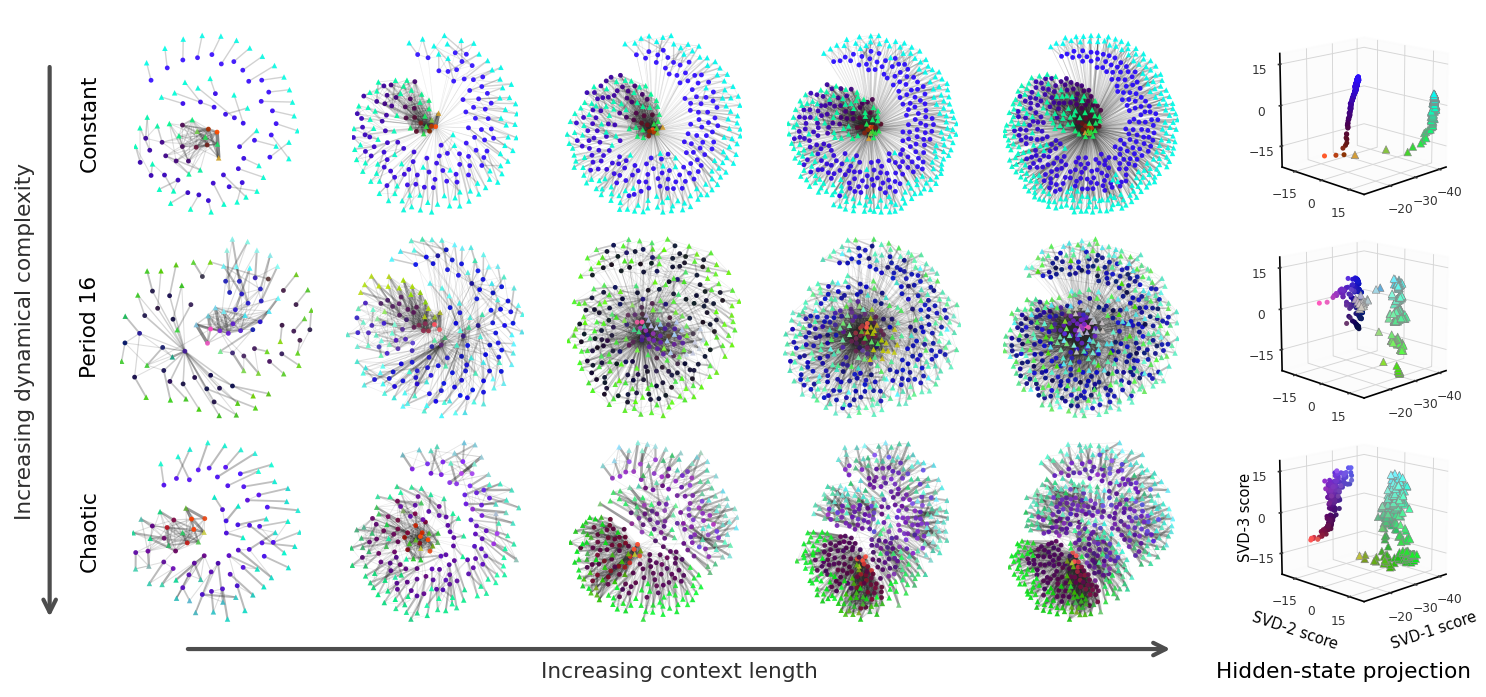

In [6]:
check_combined_figure_data(data_names=DATA_ORDER, context_token_counts=CONTEXT_TOKEN_COUNTS)
LAYER_INDEX = int(
    available_layer_indices(
        data_name=DATA_ORDER[0],
        num_tokens=CONTEXT_TOKEN_COUNTS[-1],
    )[-1]
)

combined_fig = plot_context_length_graphs_with_hidden_states(
    layer_index=LAYER_INDEX,
    data_names=DATA_ORDER,
    context_token_counts=CONTEXT_TOKEN_COUNTS,
    save=True,
    show=True,
)